In [12]:
import numba
import numpy as np
from profdata import load_profdata
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

/home/keke/.pixi/envs/py/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [15]:
@numba.jit(nopython=True, boundscheck=False, parallel=True)
def sim_matrix_impl(act_hash, res):
    N, K = act_hash.shape
    for i in range(N):
        for j in range(N):
            interp = np.bitwise_count(np.bitwise_and(act_hash[i], act_hash[j])).sum()
            un = np.bitwise_count(np.bitwise_or(act_hash[i], act_hash[j])).sum()
            res[i, j] = interp / (un + 1)

def sim_matrix(act_hash):
    N, K = act_hash.shape
    act_hash = act_hash.astype(np.int32)
    res = np.empty((N, N), dtype=np.uint32)
    sim_matrix_impl(act_hash, res)
    return res

In [16]:
data = load_profdata('pgo-data/boom_m_1.T1.prof.bin')

In [17]:
act_hash = data.threads[0].act_hash
act_hash

array([[254,   3,   0, ...,   0,   0,   0],
       [254,   3,   0, ..., 128, 131,   1],
       [  0,   0,   0, ..., 255,   0,  12],
       ...,
       [254,  15,   0, ...,   0,   0,   0],
       [254, 255, 255, ..., 255, 255, 255],
       [248,  15,   0, ...,   0,   0,   0]],
      shape=(2328, 10000), dtype=uint8)

In [37]:
inter = np.empty((act_hash.shape[0], act_hash.shape[0]))
union = np.empty((act_hash.shape[0], act_hash.shape[0]))
for i in tqdm(range(0, act_hash.shape[1] // 5, 100)):
    workset = act_hash[:, i:i+100]
    inter += np.bitwise_count(workset[:, None, :] & workset[None, :, :]).sum(axis=-1)
    un += np.bitwise_count(workset[:, None, :] | workset[None, :, :]).sum(axis=-1)
iou = inter / (un + 1)

100%|██████████| 20/20 [00:20<00:00,  1.04s/it]


In [41]:
np.save('iou.npy', iou)

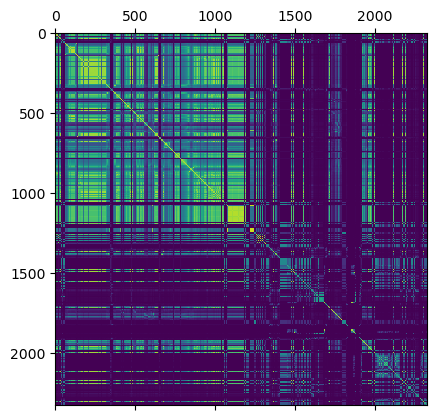

In [40]:
plt.matshow(iou, cmap='viridis', vmax=iou.max() - 1e-1)

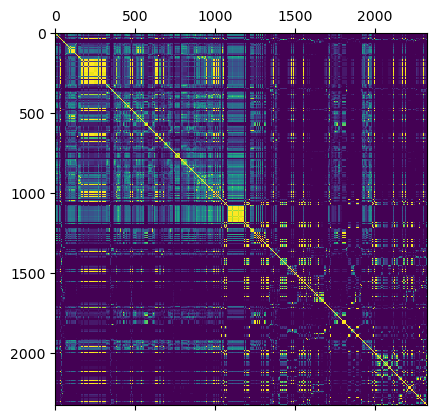

In [5]:
plt.matshow(res, cmap='viridis')

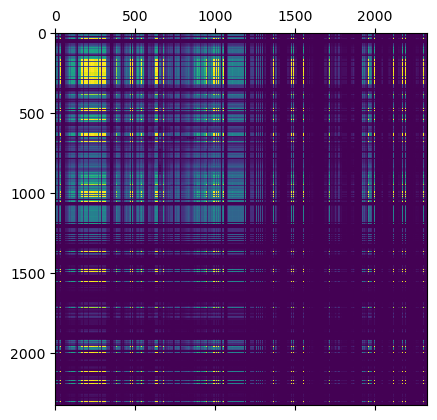

In [26]:
M = act_hash.astype(np.uint32) / 256
M = M[:, :2048]
plt.matshow(M @ M.T, cmap='viridis')